In [2]:

import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("../data/raw/ai4i2020.csv")

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(10000, 14)


In [3]:
# Statistical summary
display(df.describe())


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [4]:
# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())



Missing Values:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


In [5]:
# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())


Duplicate Records:
0


In [6]:
# Check unique values
print("\nUnique Values:")
print(df.nunique())


Unique Values:
UDI                        10000
Product ID                 10000
Type                           3
Air temperature [K]           93
Process temperature [K]       82
Rotational speed [rpm]       941
Torque [Nm]                  577
Tool wear [min]              246
Machine failure                2
TWF                            2
HDF                            2
PWF                            2
OSF                            2
RNF                            2
dtype: int64


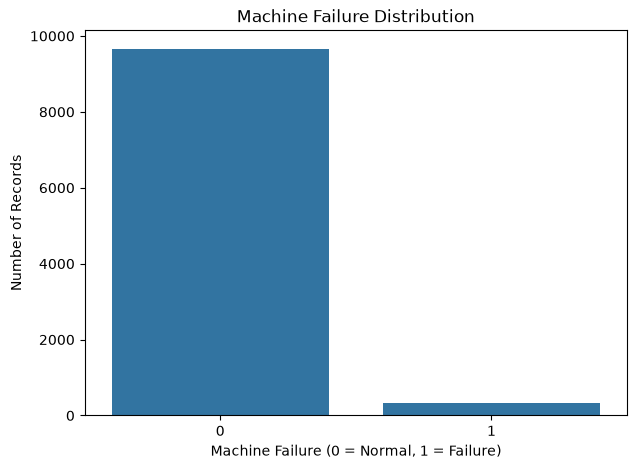

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Machine failure"
)

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = Normal, 1 = Failure)")
plt.ylabel("Number of Records")

plt.show()
S

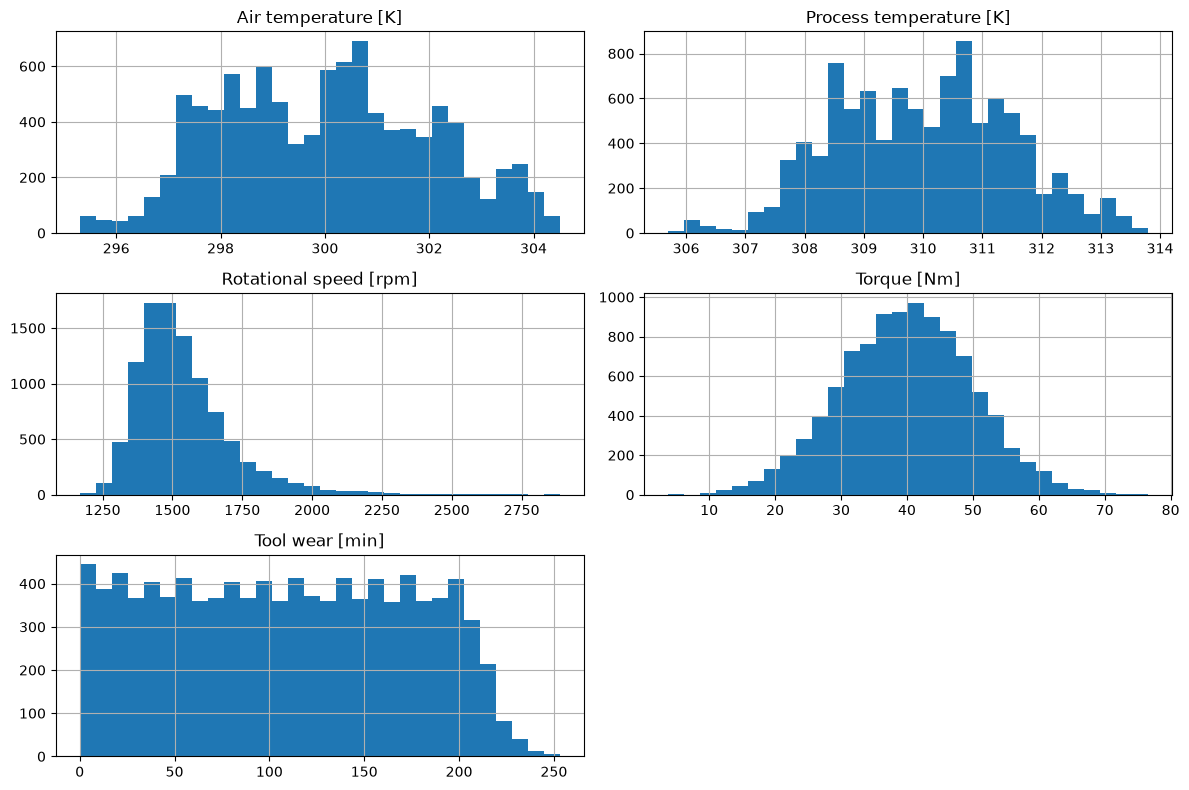

In [9]:

numerical_columns = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numerical_columns].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()


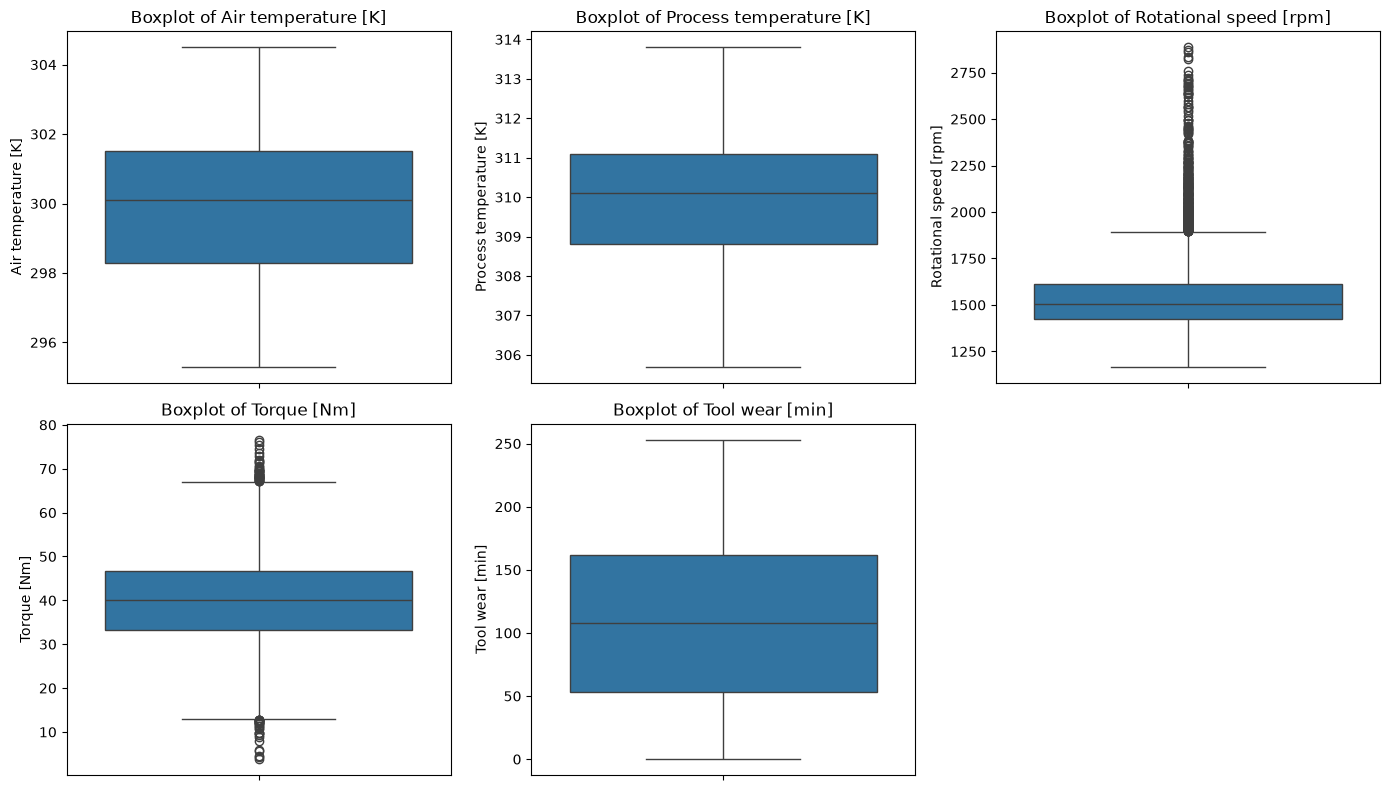

In [10]:

plt.figure(figsize=(14, 8))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(2, 3, i)

    sns.boxplot(
        y=df[column]
    )

    plt.title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()


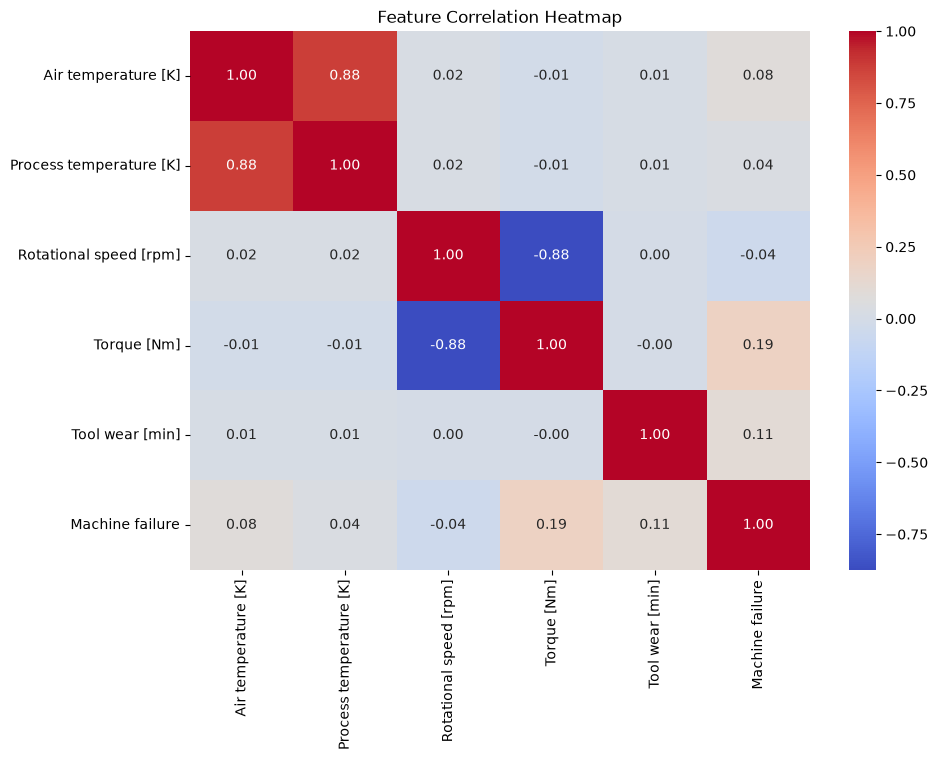

In [11]:

plt.figure(figsize=(10, 7))

correlation = df[numerical_columns + ["Machine failure"]].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Heatmap")

plt.show()


In [12]:

failure_by_type = df.groupby("Type")["Machine failure"].agg(
    ["count", "sum", "mean"]
)

failure_by_type.columns = [
    "Total Machines",
    "Failure Count",
    "Failure Rate"
]

failure_by_type["Failure Rate"] *= 100

print(failure_by_type)


      Total Machines  Failure Count  Failure Rate
Type                                             
H               1003             21      2.093719
L               6000            235      3.916667
M               2997             83      2.769436


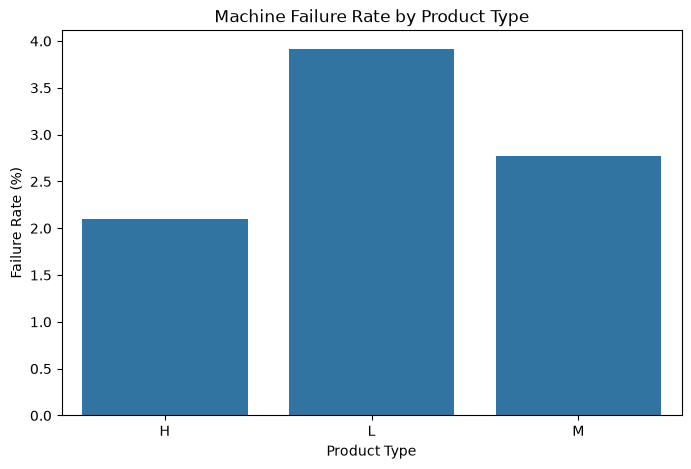

In [15]:


plot_data = failure_by_type.reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=plot_data,
    x="Type",
    y="Failure Rate"
)

plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")

plt.show()

